# 03. Sori Distribution Imputation

This notebook imputes H15's missing row-level sori distribution, how its total sori count (already imputed in `02_total_sori_imputation`) is distributed along the frond's pinna rows. We first check whether this distribution can be explained by morphometric variables; if not, we reconstruct it using a KNN-donor approach based on similar individuals, and validate the method with leave-one-out cross-validation on the 23 individuals with complete data.

## 1. Import Libraries

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

from scipy.stats import spearmanr, pearsonr
from statsmodels.stats.multitest import multipletests
from sklearn.preprocessing import StandardScaler

import sys
sys.path.append('..')
from src.plotting import heatmap_frond, heatmap_frond_ax

## 2. Load Data

We load the cleaned Sori dataset from `01_data_cleaning` and the imputed Fronds dataset from `02_total_sori_imputation`, which already includes `n_pinna_rows` and H15's imputed `n_sori_total`.

In [26]:
df_sori_clean = pd.read_csv("../data/processed/sori_clean.csv")
df_fronds_imputed = pd.read_csv("../data/processed/fronds_imputed.csv")

Quick check of the loaded data:

In [27]:
df_sori_clean.head()

,individual_id,row_id,n_sori_per_row
0,H01,86,0.0
1,H01,85,0.0
2,H01,84,0.0
3,H01,83,0.0
4,H01,82,0.0


In [28]:
df_fronds_imputed.head()

,individual_id,frond_length_cm,frond_width_cm,n_sori_total,leaf_area_cm2,n_pinna_rows,is_imputed
0,H01,63.0,8.4,1656,280.0,86,False
1,H02,42.0,5.8,1554,130.0,59,False
2,H03,68.5,8.1,1728,266.0,80,False
3,H04,66.0,7.1,1826,216.0,89,False
4,H05,60.7,6.0,1456,194.0,82,False


## 3. Isolating H15's Row-Level Data

As established in `01_data_cleaning`, H15 has no row-level sori data at all, all 86 of its rows are missing `n_sori_per_row`. We confirm this here, then set H15 aside to work with the 23 individuals with complete row-level data.

In [29]:
df_sori_clean[df_sori_clean["individual_id"] == "H15"]

,individual_id,row_id,n_sori_per_row
1118,H15,86,NaN
1119,H15,85,NaN
1120,H15,84,NaN
1121,H15,83,NaN
1122,H15,82,NaN
...,...,...,...
1199,H15,5,NaN
1200,H15,4,NaN
1201,H15,3,NaN
1202,H15,2,NaN


We filter out H15's rows, keeping only individuals with complete row-level data, used to explore and later reconstruct H15's distribution.

In [30]:
df_sori_notnull = df_sori_clean[df_sori_clean["n_sori_per_row"].notnull()]

print(f"Shape after removing H15: {df_sori_notnull.shape}")
print(f"Remaining missing values: {df_sori_notnull['n_sori_per_row'].isna().sum()}")

Shape after removing H15: (1835, 3)
Remaining missing values: 0


## 4. Exploratory Analysis

### 4.1 Sori Distribution Heatmaps

Before deciding how to impute H15's distribution, it helps to visualize the pattern followed by individuals with complete data. Each individual's reproductive heatmap allows a qualitative comparison of the general shape of the sori distribution along the frond: where the point of highest concentration is located, how symmetric the distribution is relative to the center of the fertile zone, and how much this shape varies between individuals.

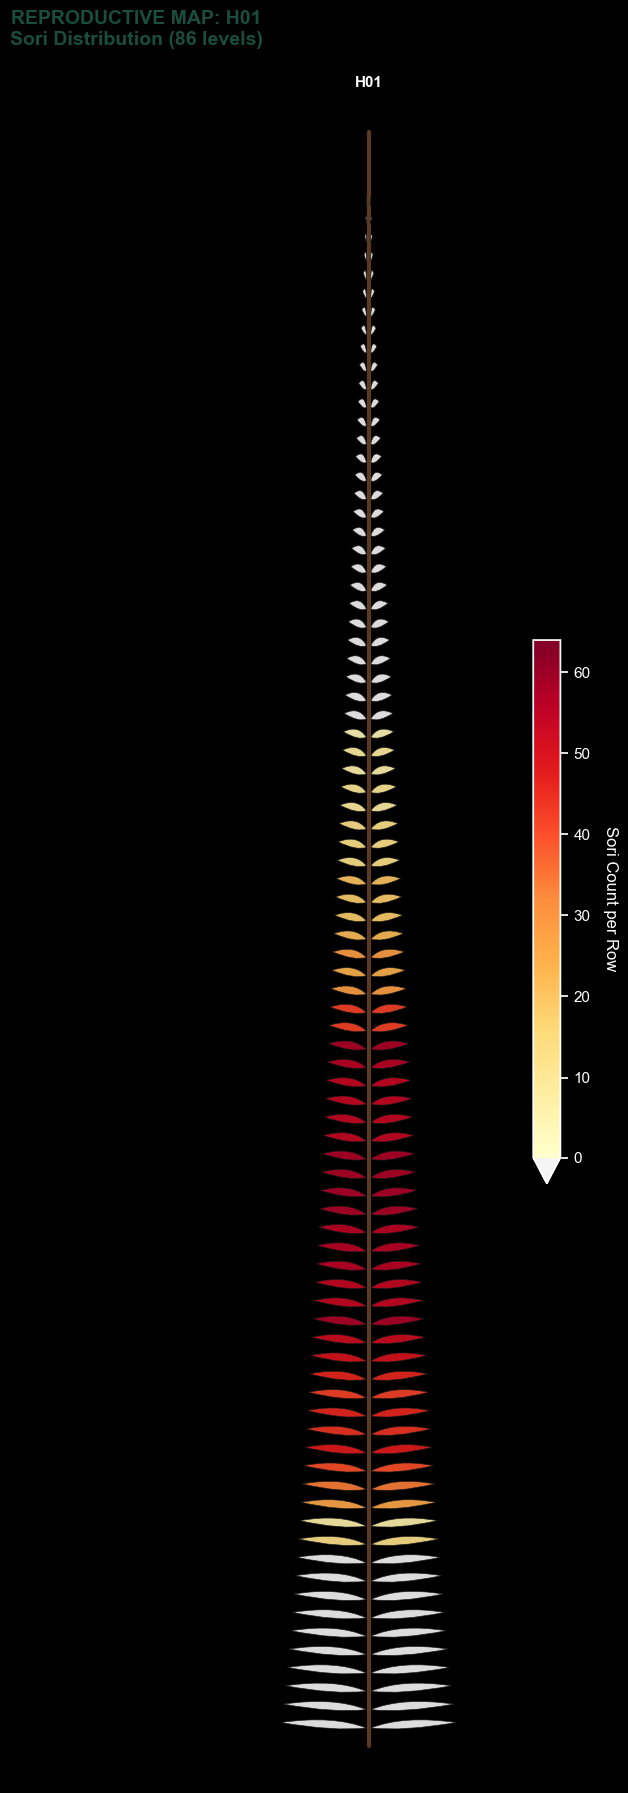

In [31]:
heatmap_frond("H01", df_sori_notnull)

We repeat this for all 23 individuals with complete data, arranged in a single grid for comparison.

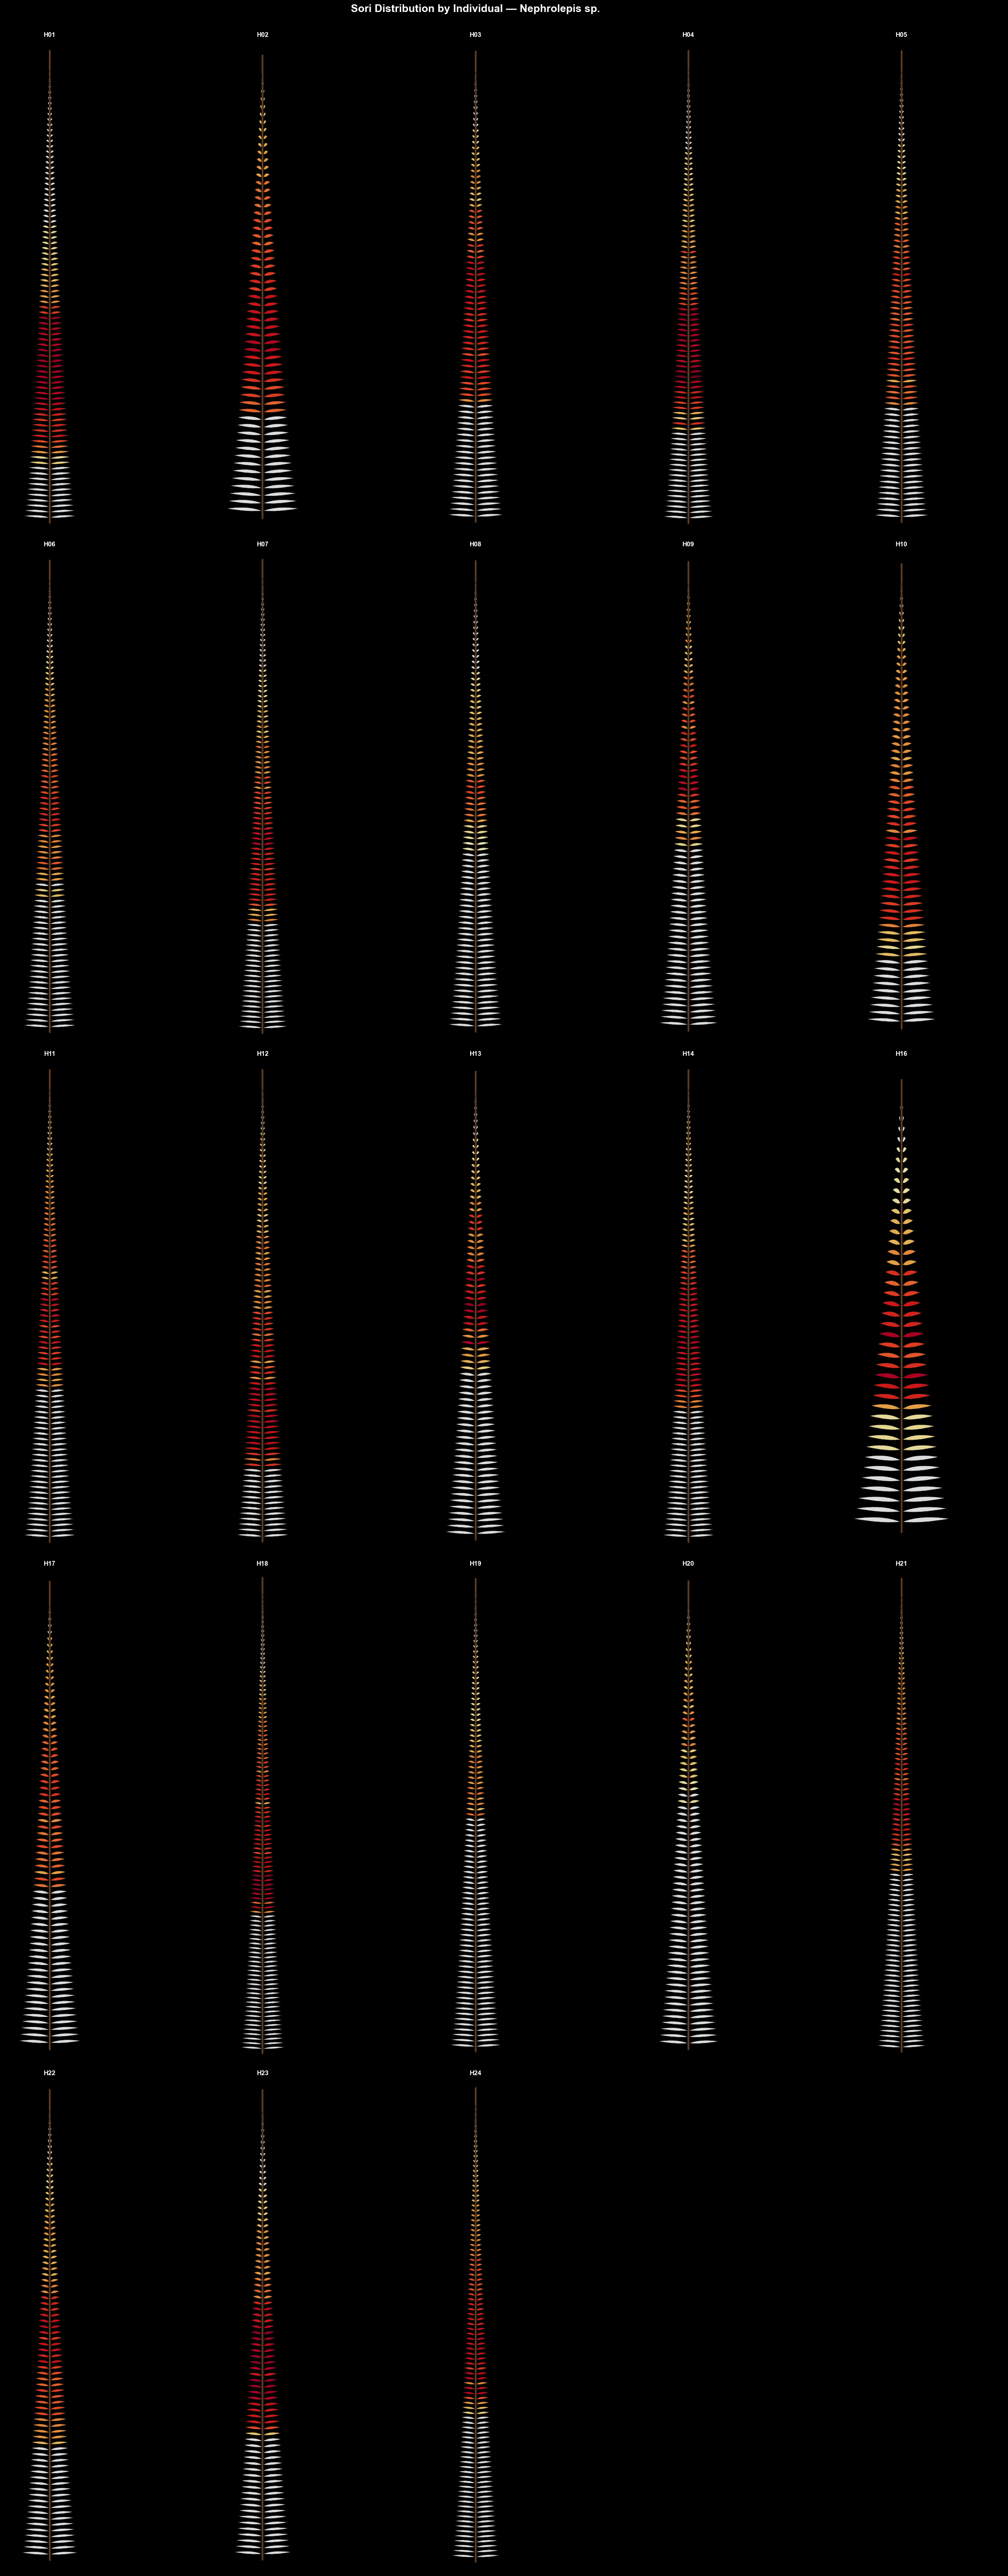

In [32]:
individuals = df_sori_notnull["individual_id"].unique()

fig, axes = plt.subplots(5, 5, figsize=(25, 60), facecolor='black')
axes = axes.flatten()

for i, individual in enumerate(individuals):
    axes[i].set_facecolor('black')
    heatmap_frond_ax(individual, axes[i], df_sori_notnull)

for j in range(len(individuals), len(axes)):
    axes[j].set_facecolor('black')
    axes[j].axis('off')

plt.suptitle('Sori Distribution by Individual — Nephrolepis sp.',
             fontsize=18, fontweight='bold', color='white', y=1.001)

plt.tight_layout()
plt.show()

Visual inspection of the 23 heatmaps shows a broadly consistent pattern: sori concentrate toward the middle-to-basal region of the fertile zone in most individuals, tapering off toward both the base and the apex. However, the exact position and intensity of this concentration varies noticeably between individuals. Section 4.2 examines this pattern quantitatively, normalizing for frond length so that individuals can be compared on a common relative scale.

### 4.2 Relative Proportion Curves by Position

To compare individuals despite having different numbers of rows, we express each frond's row position on a common 0-to-1 scale (0 = base, 1 = apex) and plot the relative proportion of sori at each position, along with the average curve across all 23 individuals.

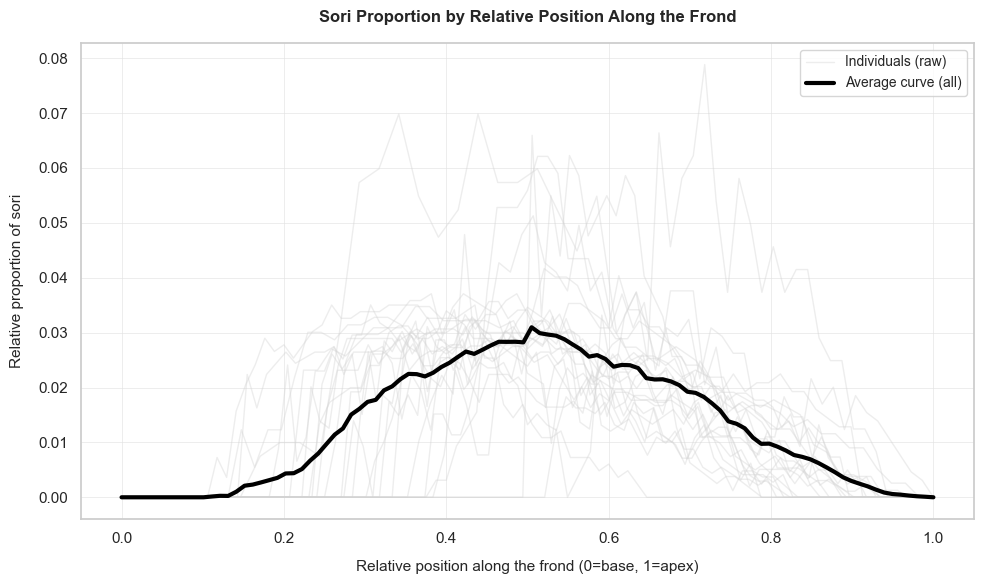

In [33]:
fig, ax = plt.subplots(figsize=(10, 6))

individuals = df_sori_notnull['individual_id'].unique()

common_grid = np.linspace(0, 1, 100)
interpolated_curves = []

for i, ind in enumerate(individuals):
    d = df_sori_notnull[df_sori_notnull.individual_id == ind].sort_values('row_id', ascending=True).reset_index(drop=True)
    total = d['n_sori_per_row'].sum()

    if total > 0:
        rel_pos = np.linspace(0, 1, len(d))
        proportion = d['n_sori_per_row'] / total

        gray_label = 'Individuals (raw)' if i == 0 else ""
        ax.plot(rel_pos, proportion, color='lightgrey', alpha=0.4, lw=1.0, label=gray_label)

        proportion_interp = np.interp(common_grid, rel_pos, proportion)
        interpolated_curves.append(proportion_interp)

avg_proportion = np.mean(interpolated_curves, axis=0)
ax.plot(common_grid, avg_proportion, color='black', lw=3.0, label='Average curve (all)', zorder=5)

ax.set_xlabel('Relative position along the frond (0=base, 1=apex)', fontsize=11, labelpad=10)
ax.set_ylabel('Relative proportion of sori', fontsize=11, labelpad=10)
ax.set_title('Sori Proportion by Relative Position Along the Frond', fontsize=12, fontweight='bold', pad=15)

ax.set_xlim(-0.05, 1.05)
ax.grid(True, color='#e2e2e2', linestyle='-', linewidth=0.6, alpha=0.7)
ax.legend(fontsize=10, loc='upper right')

plt.tight_layout()
plt.show()

Visual inspection shows that, while the exact position and magnitude of sori vary between individuals, the general shape of the distribution, increasing concentration from the base, a peak toward the center of the fertile zone, and a decline toward the apex, remains relatively consistent. To capture this shape quantitatively and comparably across individuals, regardless of each frond's specific row count, we extract 5 reference points along the fertile zone (base, first quartile, center, third quartile, and apex), interpolating the sori count at each of these relative positions. This reduces each individual's full distribution to a compact set of 5 values, which allows us to explore whether these characteristic points correlate with the frond's morphometric variables, evaluating whether there is a biometric basis for imputing H15's distribution shape from its most similar individuals.

## 5. Feature Extraction: Characteristic Points of the Fertile Zone

We reduce each individual's full row-level distribution to 5 characteristic points along its fertile zone, base, first quartile, center, third quartile, and apex, interpolating the sori count at each of these relative positions. This gives a compact, comparable representation of distribution shape across individuals with different numbers of rows, which we use in Section 6 to test whether shape correlates with frond morphometrics.

In [34]:
df_sori_notnull = df_sori_notnull.copy()

# Relative position (0 = base, 1 = apex)
df_sori_notnull["n_rows_total"] = df_sori_notnull.groupby("individual_id")["row_id"].transform("max")
df_sori_notnull["relative_position"] = df_sori_notnull["row_id"] / df_sori_notnull["n_rows_total"]

def extract_five_points(group):
    """
    Interpolates the sori count at 5 evenly spaced positions across the
    fertile zone (the range between the first and last row with sori > 0),
    ordered from base (0) to apex (1).
    """
    group = group.sort_values("relative_position")
    with_sori = group[group["n_sori_per_row"] > 0]

    if with_sori.empty:
        return pd.Series({
            "base_pos": np.nan, "sori_base": np.nan,
            "q1_pos": np.nan, "sori_q1": np.nan,
            "center_pos": np.nan, "sori_center": np.nan,
            "q3_pos": np.nan, "sori_q3": np.nan,
            "apex_pos": np.nan, "sori_apex": np.nan,
        })

    zone_start = with_sori["relative_position"].min()
    zone_end = with_sori["relative_position"].max()

    x = group["relative_position"].values
    y = group["n_sori_per_row"].values

    fertile_length = zone_end - zone_start
    positions = zone_start + np.array([0, 0.25, 0.5, 0.75, 1.0]) * fertile_length
    values = np.interp(positions, x, y)

    return pd.Series({
        "base_pos": positions[0], "sori_base": values[0],
        "q1_pos": positions[1], "sori_q1": values[1],
        "center_pos": positions[2], "sori_center": values[2],
        "q3_pos": positions[3], "sori_q3": values[3],
        "apex_pos": positions[4], "sori_apex": values[4],
    })

df_shape_metrics = (
    df_sori_notnull.groupby("individual_id")
    .apply(extract_five_points, include_groups=False)
    .reset_index()
)

df_shape_vs_morphometry = df_shape_metrics.merge(
    df_fronds_imputed[df_fronds_imputed["individual_id"] != "H15"][
        ["individual_id", "frond_length_cm", "frond_width_cm", "n_sori_total", "n_pinna_rows"]
    ],
    on="individual_id"
)

df_shape_vs_morphometry.round(3)

,individual_id,base_pos,sori_base,q1_pos,sori_q1,center_pos,sori_center,q3_pos,sori_q3,apex_pos,sori_apex,frond_length_cm,frond_width_cm,n_sori_total,n_pinna_rows
0,H01,0.128,12.0,0.256,52.0,0.384,54.0,0.512,22.0,0.640,4.0,63.00,8.4,1656,86
1,H02,0.237,36.0,0.419,50.0,0.602,38.0,0.784,26.0,0.966,4.0,42.00,5.8,1554,59
2,H03,0.262,28.0,0.409,47.5,0.556,52.0,0.703,13.5,0.850,4.0,68.50,8.1,1728,80
3,H04,0.202,16.0,0.351,52.5,0.500,38.0,0.649,15.5,0.798,6.0,66.00,7.1,1826,89
4,H05,0.256,30.0,0.396,39.0,0.537,48.0,0.677,27.0,0.817,6.0,60.70,6.0,1456,82
5,H06,0.294,18.0,0.426,32.5,0.559,39.0,0.691,27.5,0.824,2.0,62.40,6.9,1290,85
6,H07,0.242,32.0,0.376,46.0,0.511,40.0,0.646,17.5,0.780,2.0,67.20,7.8,1590,91
7,H08,0.395,2.0,0.491,34.0,0.586,26.0,0.682,17.5,0.778,4.0,55.00,6.1,644,81
8,H09,0.405,10.0,0.551,52.0,0.696,40.0,0.841,16.0,0.986,4.0,66.00,6.8,1296,74
9,H10,0.161,18.0,0.351,46.5,0.540,35.0,0.730,26.5,0.919,4.0,51.30,6.4,1464,62


With these 5 characteristic points computed for each individual, we can explore whether they relate to frond morphometrics, that is, whether the shape of the sori distribution depends on frond size, or whether it is essentially universal across individuals regardless of dimensions.

## 6. Do Morphometric Variables Predict Curve Shape?

### 6.1 Scatter Matrix

With the 5 characteristic points computed for each individual, we can explore the question directly: does the shape of the sori distribution depend on frond size, or is it essentially universal across individuals? We plot each of the 5 points (`sori_base`, `sori_q1`, `sori_center`, `sori_q3`, `sori_apex`) against each of the 4 morphometric variables (`frond_length_cm`, `frond_width_cm`, `n_sori_total`, `n_pinna_rows`), along with their regression line, a 20-panel scatter matrix that lets us visually identify at which points of the fertile zone, if any, sori count shows a stronger relationship with frond size, before quantifying it formally.

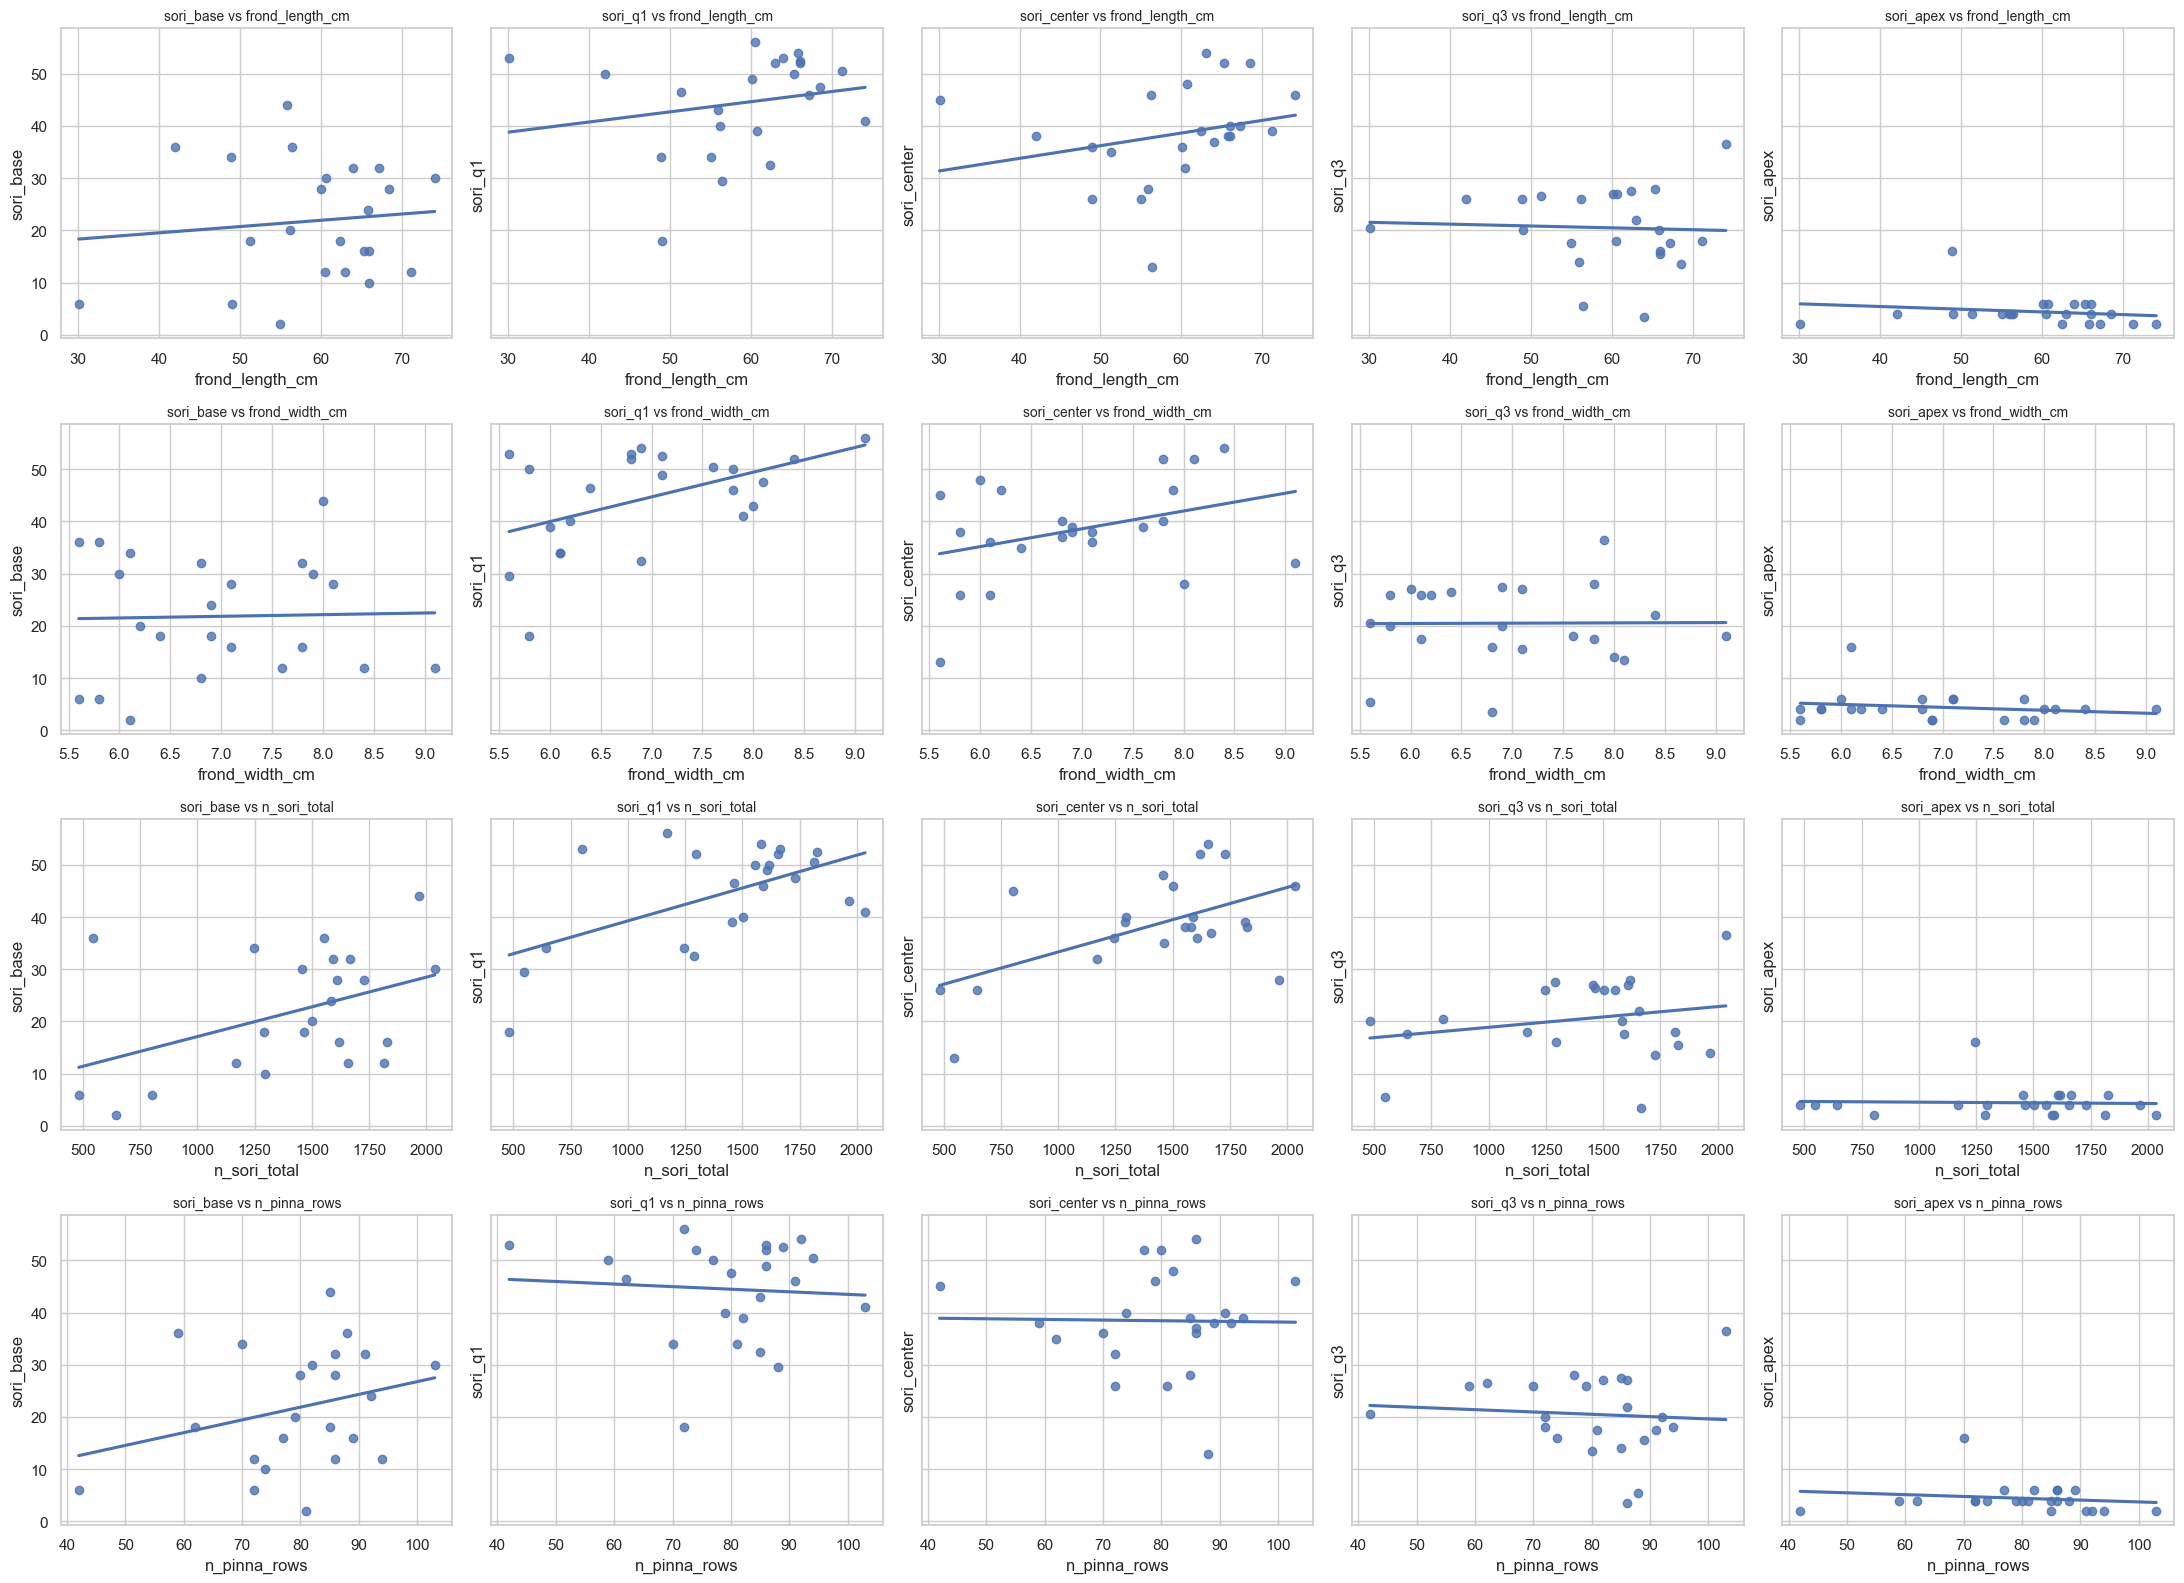

In [35]:
morphometric_vars = ["frond_length_cm", "frond_width_cm", "n_sori_total", "n_pinna_rows"]
sori_points = ["sori_base", "sori_q1", "sori_center", "sori_q3", "sori_apex"]

fig, axes = plt.subplots(4, 5, figsize=(22, 16), sharey=True)

for row, var in enumerate(morphometric_vars):
    for col, point in enumerate(sori_points):
        sns.regplot(x=var, y=point, data=df_shape_vs_morphometry, ax=axes[row, col], ci=None)
        axes[row, col].set_title(f"{point} vs {var}", fontsize=10)

plt.tight_layout()
plt.show()

### 6.2 Spearman Correlation

We use Spearman correlation rather than Pearson, since some points (particularly `sori_apex`) show observations that clearly depart from the general trend of the rest of the individuals. Spearman, being rank-based, is more robust to these deviations and does not require the relationship to be linear, only monotonic.

In [36]:
correlation_results = []

for var in morphometric_vars:
    for point in sori_points:
        x = df_shape_vs_morphometry[var]
        y = df_shape_vs_morphometry[point]

        rho, p_value = spearmanr(x, y)

        correlation_results.append({
            "variable": var,
            "sori_point": point,
            "spearman_rho": rho,
            "spearman_p": p_value,
        })

df_shape_correlations = pd.DataFrame(correlation_results)
df_shape_correlations.round(3)

,variable,sori_point,spearman_rho,spearman_p
0,frond_length_cm,sori_base,-0.006,0.978
1,frond_length_cm,sori_q1,0.274,0.206
2,frond_length_cm,sori_center,0.517,0.012
3,frond_length_cm,sori_q3,-0.148,0.501
4,frond_length_cm,sori_apex,-0.198,0.366
5,frond_width_cm,sori_base,-0.002,0.991
6,frond_width_cm,sori_q1,0.363,0.089
7,frond_width_cm,sori_center,0.339,0.114
8,frond_width_cm,sori_q3,-0.036,0.869
9,frond_width_cm,sori_apex,-0.052,0.815


The table above contains 20 simultaneous correlation tests (4 morphometric variables × 5 fertile-zone points). When testing multiple hypotheses on the same dataset, the probability of finding at least one "significant" result by chance alone increases, this is the multiple comparisons problem. With a threshold of p < 0.05 and 20 independent tests, we would expect approximately 1 false positive even if no real underlying relationship existed (20 × 0.05 = 1). Two values fall below that threshold, `frond_length_cm`/`sori_center` (rho = 0.517, p = 0.012) and `n_sori_total`/`sori_center` (rho = 0.434, p = 0.039), a number consistent with what chance alone would predict without correction.

### 6.3 Multiple Testing Correction (Benjamini-Hochberg)

We apply two multiple-testing corrections for comparison: Bonferroni (conservative, controls the probability of any false positive) and Benjamini-Hochberg (less conservative, controls the expected proportion of false positives among significant results).

In [37]:
reject_bonf, pvals_bonf, _, _ = multipletests(df_shape_correlations["spearman_p"], method="bonferroni")
reject_bh, pvals_bh, _, _ = multipletests(df_shape_correlations["spearman_p"], method="fdr_bh")

df_shape_correlations["spearman_p_bonferroni"] = pvals_bonf
df_shape_correlations["spearman_sig_bonferroni"] = reject_bonf
df_shape_correlations["spearman_p_bh"] = pvals_bh
df_shape_correlations["spearman_sig_bh"] = reject_bh

df_shape_correlations.round(3)

,variable,sori_point,spearman_rho,spearman_p,spearman_p_bonferroni,spearman_sig_bonferroni,spearman_p_bh,spearman_sig_bh
0,frond_length_cm,sori_base,-0.006,0.978,1.000,False,0.991,False
1,frond_length_cm,sori_q1,0.274,0.206,1.000,False,0.588,False
2,frond_length_cm,sori_center,0.517,0.012,0.231,False,0.231,False
3,frond_length_cm,sori_q3,-0.148,0.501,1.000,False,0.835,False
4,frond_length_cm,sori_apex,-0.198,0.366,1.000,False,0.732,False
5,frond_width_cm,sori_base,-0.002,0.991,1.000,False,0.991,False
6,frond_width_cm,sori_q1,0.363,0.089,1.000,False,0.456,False
7,frond_width_cm,sori_center,0.339,0.114,1.000,False,0.456,False
8,frond_width_cm,sori_q3,-0.036,0.869,1.000,False,0.991,False
9,frond_width_cm,sori_apex,-0.052,0.815,1.000,False,0.991,False


After applying the Benjamini-Hochberg correction, none of the 20 correlations remain significant. This indicates that the position of highest sori concentration does not depend detectably on any single morphometric variable considered in isolation. However, this does not rule out that useful information exists in the combination of all morphometric variables at once: two individuals could be very similar in their overall morphometric profile (length, width, total sori, row count) without any single variable showing a strong correlation with distribution shape.

This is largely a consequence of sample size: with n=23, even a moderate correlation (rho ≈ 0.5) requires a raw p-value well below 0.05 to survive Bonferroni or BH correction across 20 simultaneous tests — the two nominally significant correlations found in Section 6.2 (rho = 0.52 and 0.43) were too weak relative to this small sample to clear that stricter bar.

For this reason, we adopt a weighted KNN-donor approach: instead of modeling curve shape as a function of a single morphometric variable, we identify the K individuals most similar to H15 in the joint space of standardized morphometric variables (Euclidean distance), and use the real distribution shape of those neighbors, normalized to relative proportions, not absolute values, as the reference for imputing H15's distribution. Each neighbor contributes to the final curve in inverse proportion to its distance: individuals more similar to H15 carry more weight in the average. This approach does not depend on an explicit linear or monotonic relationship between any single variable and curve shape, already ruled out by the correlation analysis above, only on morphometrically similar individuals tending to share similar distribution patterns overall.

## 7. KNN-Donor Imputation

### 7.1 Selecting K via Leave-One-Out Cross-Validation

#### 7.1.1 Why Leave-One-Out?

H15's distribution curve will be generated entirely by imputation, there is no real observation to compare it against directly, so we cannot calculate a direct prediction error for H15 itself. The alternative is indirect empirical validation: using the 23 individuals with complete data, we temporarily hide each one's real distribution, reconstruct it using only the other 22 as potential donors (excluding H15 entirely from the donor pool, exactly as it will be excluded when H15 is the target), and compare the reconstructed curve against the real one we already know.

In other words: if the algorithm reasonably reconstructs the curve shape for individuals where we do know the right answer, that gives evidence (not proof) that it will do the same for H15, where we don't. We use this leave-one-out framework not only to validate the method overall, but also to choose K itself, rather than fixing it arbitrarily before checking how it performs.

#### 7.1.2 A Starting Heuristic: K ≈ √n

With 23 potential donors, a common rule of thumb for KNN when there is no prior reason to prefer a specific value is K ≈ √n, where n is the number of candidates, here, √23 ≈ 4.8, rounding to 5. This is not proof that K=5 is optimal, only a reasonable starting point that avoids picking an arbitrary number out of nowhere. We use it as the center of the range tested empirically below, not as the final answer.

#### 7.1.3 LOO Reconstruction Function

We define a function that reconstructs an individual's distribution curve using the same weighted KNN procedure that will later be used to impute H15, but excluding that individual (and H15) from the donor pool, parameterized by `k`, so it can be tested across multiple values.

In [38]:
predictor_vars = ["frond_length_cm", "frond_width_cm", "n_sori_total", "leaf_area_cm2", "n_pinna_rows"]
grid = np.linspace(0, 1, 200)


def reconstruct_loo_curve(test_individual, k, features=predictor_vars):
    """
    Reconstructs the sori distribution curve of `test_individual` using the
    same weighted morphometric KNN procedure used to impute H15, excluding
    `test_individual` (and H15) from the donor pool. Returns the
    reconstructed sori count per row, the reconstructed relative proportion,
    and the list of neighbors used.
    """
    donors = df_fronds_imputed[
        (df_fronds_imputed.individual_id != test_individual) &
        (df_fronds_imputed.individual_id != "H15")
    ].reset_index(drop=True)
    target_row = df_fronds_imputed[df_fronds_imputed.individual_id == test_individual].iloc[0]

    scaler = StandardScaler()
    X_donors = scaler.fit_transform(donors[features])
    X_target = scaler.transform(pd.DataFrame([target_row[features].values], columns=features))

    donors = donors.copy()
    donors["dist"] = np.sqrt(((X_donors - X_target) ** 2).sum(axis=1))
    donors_sorted = donors.sort_values("dist").reset_index(drop=True)

    neighbors = donors_sorted.head(k)["individual_id"].tolist()
    weights = 1 / donors_sorted.head(k)["dist"].values
    weights = weights / weights.sum()

    interpolated_curves = []
    for neighbor in neighbors:
        d = df_sori_notnull[df_sori_notnull.individual_id == neighbor].sort_values("row_id", ascending=True).reset_index(drop=True)
        rel_pos = np.linspace(0, 1, len(d))
        proportion = d["n_sori_per_row"] / d["n_sori_per_row"].sum()
        interpolated_curves.append(np.interp(grid, rel_pos, proportion))

    avg_curve = np.average(np.array(interpolated_curves), axis=0, weights=weights)
    avg_curve /= avg_curve.sum()

    n_rows_test = int(target_row["n_pinna_rows"])
    n_sori_test = int(target_row["n_sori_total"])
    pos_test = np.linspace(0, 1, n_rows_test)
    proportion_test = np.interp(pos_test, grid, avg_curve)
    proportion_test /= proportion_test.sum()

    sori_reconstructed = np.round(proportion_test * n_sori_test).astype(int)
    residual = n_sori_test - sori_reconstructed.sum()
    sori_reconstructed[np.argmax(sori_reconstructed)] += residual

    return sori_reconstructed, proportion_test, neighbors

#### 7.1.4 Testing K Across a Range of Values

We run the full leave-one-out validation (all 23 individuals) for a range of K values around the √n heuristic (K = 3, 5, 7, 9, 11), and compare their average performance to decide which K to use for imputing H15.

In [39]:
k_candidates = [3, 5, 7, 9, 11]
k_summary = []

for k in k_candidates:
    correlations = []
    maes = []
    for test_individual in df_sori_notnull["individual_id"].unique():
        d_real = df_sori_notnull[df_sori_notnull.individual_id == test_individual].sort_values("row_id", ascending=True).reset_index(drop=True)
        real_counts = d_real["n_sori_per_row"].values
        real_proportion = real_counts / real_counts.sum()

        reconstructed_counts, reconstructed_proportion, _ = reconstruct_loo_curve(test_individual, k=k)

        mae = np.mean(np.abs(real_counts - reconstructed_counts))
        r, _ = pearsonr(real_proportion, reconstructed_proportion)

        correlations.append(r)
        maes.append(mae)

    k_summary.append({
        "k": k,
        "mean_correlation": np.mean(correlations),
        "mean_mae": np.mean(maes),
    })

df_k_selection = pd.DataFrame(k_summary)
df_k_selection.round(3)

,k,mean_correlation,mean_mae
0,3,0.738,8.318
1,5,0.759,7.975
2,7,0.776,7.775
3,9,0.784,7.665
4,11,0.780,7.781


#### 7.1.5 Selecting K

Performance improves consistently from K=3 to K=9 in both metrics (mean correlation: 0.738 → 0.784; mean MAE: 8.318 → 7.665), then slightly declines at K=11 (correlation 0.780, MAE 7.781), consistent with a bias-variance tradeoff: too few neighbors makes the average curve noisy and dependent on individual donors, while too many dilutes it toward a generic dataset-wide pattern, losing individual specificity.

**K=9 is selected**, outperforming both the √n heuristic (K=5) and all other candidates tested. This is a meaningful deviation from the initial heuristic, and illustrates why it was tested empirically rather than assumed.

In [40]:
k_selected = 9
print(f"Selected K: {k_selected}")

Selected K: 9


### 7.2 Finding Neighbors and Reconstructing H15's Curve

Using the K selected in Section 7.1.5, we find H15's nearest neighbors in the standardized morphometric space, build a weighted average relative-proportion curve from their real distributions, and rescale that curve to H15's own number of rows and imputed total sori count (from `02_total_sori_imputation`).

In [41]:
donors = df_fronds_imputed[df_fronds_imputed.individual_id != "H15"].reset_index(drop=True)
h15_row = df_fronds_imputed[df_fronds_imputed.individual_id == "H15"].iloc[0]

scaler = StandardScaler()
X_donors = scaler.fit_transform(donors[predictor_vars])
X_h15 = scaler.transform(pd.DataFrame([h15_row[predictor_vars].values], columns=predictor_vars))

donors["dist"] = np.sqrt(((X_donors - X_h15) ** 2).sum(axis=1))
donors_sorted = donors.sort_values("dist").reset_index(drop=True)
donors_sorted[["individual_id", "dist"]]

,individual_id,dist
0,H17,1.582620
1,H22,1.678067
2,H08,1.915424
3,H20,1.994823
4,H05,2.008470
5,H19,2.063538
6,H10,2.118432
7,H02,2.392575
8,H09,2.636119
9,H06,2.642725


We select the K individuals selected in Section 7.1.5 and weight each by the inverse of its distance to H15, so more similar individuals contribute more to the final curve.

In [42]:
K = k_selected  # defined in Section 7.1.5
neighbors_h15 = donors_sorted.head(K)["individual_id"].tolist()
weights_h15 = 1 / donors_sorted.head(K)["dist"].values
weights_h15 = weights_h15 / weights_h15.sum()

print(f"Neighbors (K={K}): {neighbors_h15}")
print(f"Weights: {weights_h15.round(3)}")

Neighbors (K=9): ['H17', 'H22', 'H08', 'H20', 'H05', 'H19', 'H10', 'H02', 'H09']
Weights: [0.14  0.132 0.116 0.111 0.111 0.108 0.105 0.093 0.084]


For each neighbor, we compute its relative-proportion curve (Section 4.2), interpolate it onto a common grid, and combine the curves into a single weighted average. This average curve is then rescaled to H15's own frond: interpolated onto its rows, and multiplied by its imputed total sori count (rounding to whole sori, with any rounding residual assigned to the row of highest density to preserve the exact total).

In [43]:
N_SORI_H15 = int(h15_row["n_sori_total"])
N_ROWS_H15 = int(h15_row["n_pinna_rows"])

interpolated_curves = []
for neighbor in neighbors_h15:
    d = df_sori_notnull[df_sori_notnull.individual_id == neighbor].sort_values("row_id", ascending=True).reset_index(drop=True)
    rel_pos = np.linspace(0, 1, len(d))
    proportion = d["n_sori_per_row"] / d["n_sori_per_row"].sum()
    interpolated_curves.append(np.interp(grid, rel_pos, proportion))

avg_curve = np.average(np.array(interpolated_curves), axis=0, weights=weights_h15)
avg_curve /= avg_curve.sum()

pos_h15 = np.linspace(0, 1, N_ROWS_H15)
proportion_h15 = np.interp(pos_h15, grid, avg_curve)
proportion_h15 /= proportion_h15.sum()
sori_h15 = np.round(proportion_h15 * N_SORI_H15).astype(int)

residual = N_SORI_H15 - sori_h15.sum()
sori_h15[np.argmax(sori_h15)] += residual

df_sori_h15_imputed = pd.DataFrame({
    "individual_id": "H15",
    "row_id": np.arange(N_ROWS_H15, 0, -1),
    "n_sori_per_row": sori_h15[::-1]
})

print(f"Total imputed sori: {df_sori_h15_imputed.n_sori_per_row.sum()} (target: {N_SORI_H15})")
df_sori_h15_imputed

Total imputed sori: 1141 (target: 1141)


,individual_id,row_id,n_sori_per_row
0,H15,86,0
1,H15,85,0
2,H15,84,0
3,H15,83,1
4,H15,82,1
...,...,...,...
81,H15,5,0
82,H15,4,0
83,H15,3,0
84,H15,2,0


H15's K=9 morphometrically closest individuals are H17, H22, H08, H20, H05, H19, H10, H02, and H09, weighted from 0.14 (H17, closest) down to 0.084 (H09, farthest) based on Euclidean distance in the standardized space of the 5 morphometric variables. Their relative-proportion curves were combined into a single weighted average, then rescaled to H15's 86 rows and its imputed total of 1141 sori, the reconstructed distribution matches the target total exactly (1141), with the rounding residual absorbed by the row of highest density.

### 7.3 Visual Check Against Neighbors

Before accepting the imputed curve as final, it helps to visually verify that H15's reconstructed shape is consistent with the real curves of its neighbors, and not an artifact of the interpolation or weighting process. We overlay the relative-proportion curves of the 9 neighbors used together with H15's imputed curve (in black), all expressed on the same relative-position scale (0=base, 1=apex), which allows a direct shape comparison.

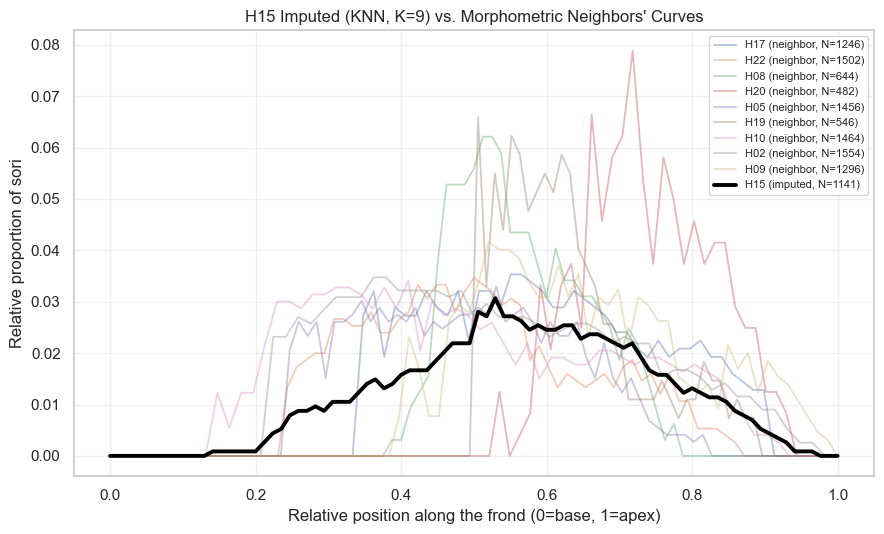

In [44]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for neighbor in neighbors_h15:
    d = df_sori_notnull[df_sori_notnull.individual_id == neighbor].sort_values("row_id", ascending=True).reset_index(drop=True)
    total = d["n_sori_per_row"].sum()
    rel_pos = np.linspace(0, 1, len(d))
    proportion = d["n_sori_per_row"] / total
    ax.plot(rel_pos, proportion, alpha=0.4, lw=1.3, label=f"{neighbor} (neighbor, N={int(total)})")

df_sori_h15_sorted = df_sori_h15_imputed.sort_values("row_id", ascending=True).reset_index(drop=True)
pos_h15 = np.linspace(0, 1, len(df_sori_h15_sorted))
proportion_h15 = df_sori_h15_sorted["n_sori_per_row"] / df_sori_h15_sorted["n_sori_per_row"].sum()
ax.plot(pos_h15, proportion_h15, color="black", lw=2.8, label="H15 (imputed, N=1141)")

ax.set_xlabel("Relative position along the frond (0=base, 1=apex)")
ax.set_ylabel("Relative proportion of sori")
ax.set_title(f"H15 Imputed (KNN, K={K}) vs. Morphometric Neighbors' Curves")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

H15's imputed curve (black) shows a smooth, unimodal shape consistent with its neighbors: it rises from near zero at the base, peaks around relative position 0.5–0.55, and decays gradually toward the apex. This matches the general envelope traced by the 9 neighbor curves, none of which show H15 falling outside the expected range, there is no sign of a flat, edge-shifted, or spurious profile that would suggest an artifact of the interpolation or weighting. One expected feature worth noting: H15's peak amplitude (~0.03) is lower than most individual neighbor peaks (~0.05–0.08), since neighbors peak at different relative positions (e.g., H20 peaks late near 0.8, H08 peaks early near 0.35); averaging curves whose maxima are not aligned in position naturally flattens the resulting peak. This is a statistical consequence of the aggregation, not evidence against the imputation.

### 7.4 Heatmap of H15 and Its Neighbors

As a complementary check to the overlaid curves in Section 7.3, we visualize each individual's full spatial heatmap side by side, H15 (imputed) together with its K=9 KNN neighbors, following the same per-frond heatmap layout used in Section 4.1. This lets us confirm that H15's imputed spatial pattern (concentration, symmetry, banding) looks visually consistent with real neighbor data, not just its 1-D relative-proportion curve.

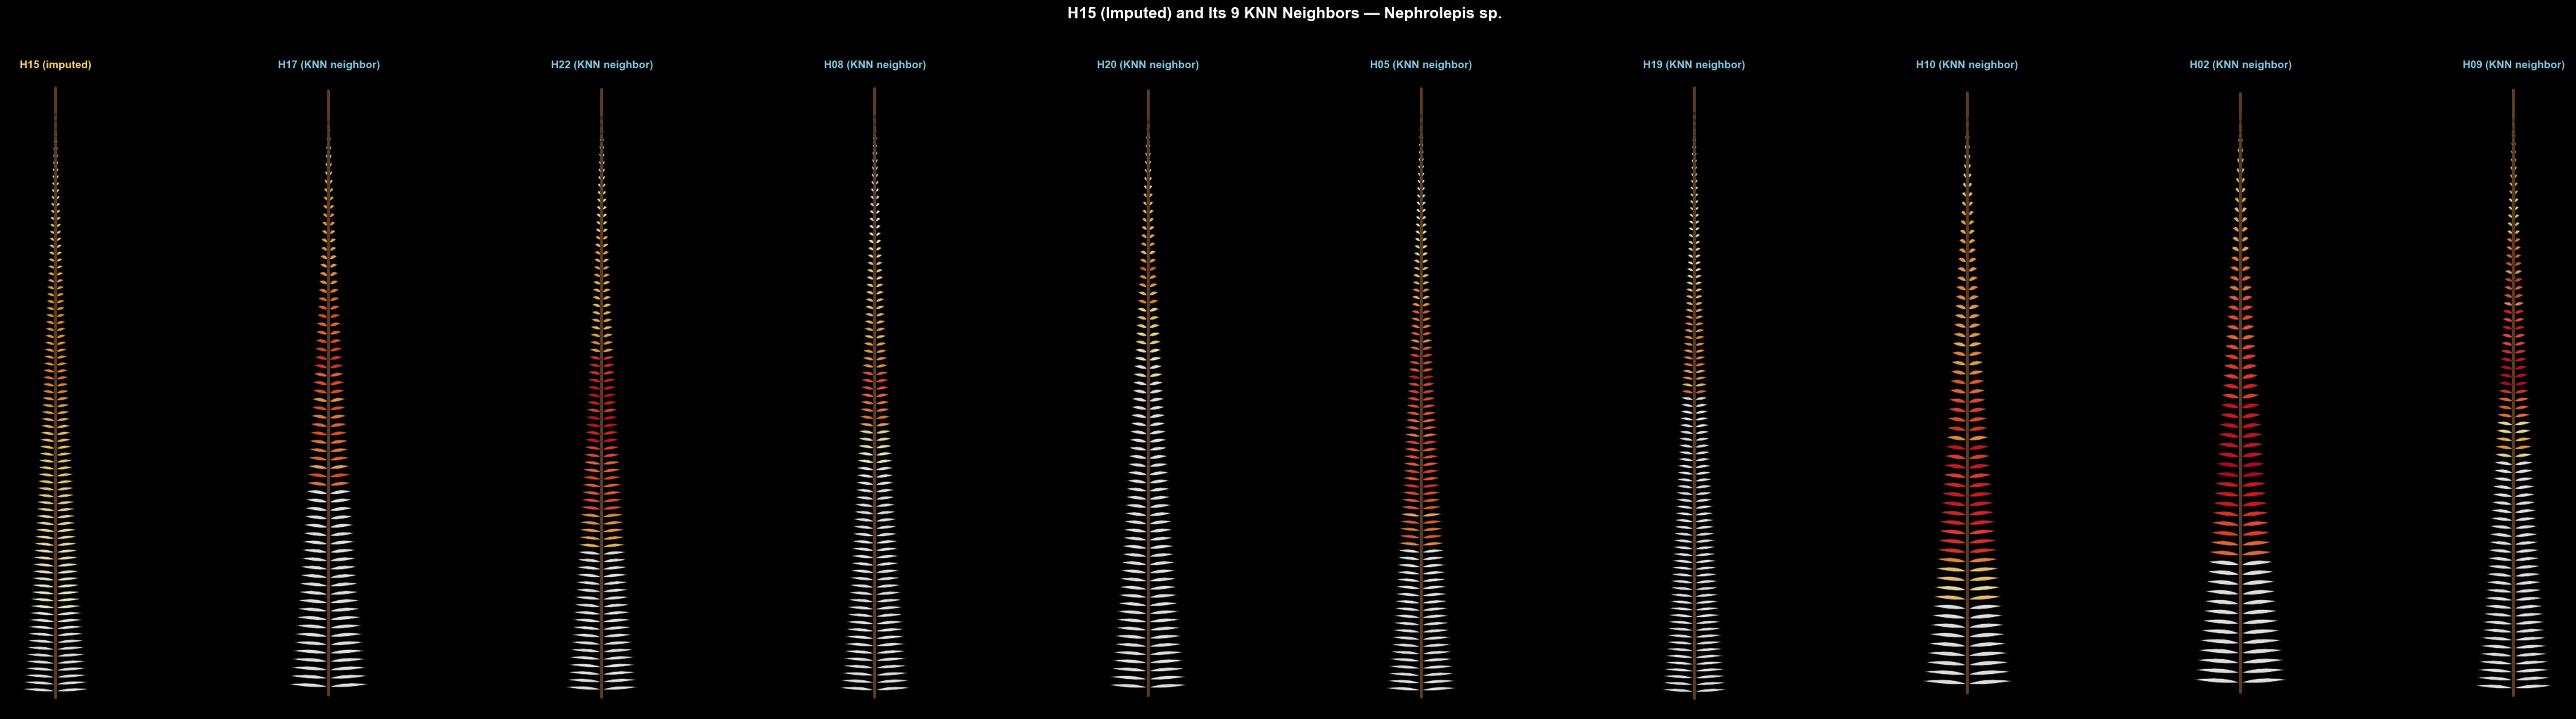

In [45]:
df_sori_display = pd.concat([
    df_sori_notnull[["individual_id", "row_id", "n_sori_per_row"]],
    df_sori_h15_imputed[["individual_id", "row_id", "n_sori_per_row"]]
], ignore_index=True)

individuals_plot = ["H15"] + neighbors_h15

fig, axes = plt.subplots(1, len(individuals_plot), figsize=(4 * len(individuals_plot), 10), facecolor="black")
axes = axes.flatten()

for i, individual in enumerate(individuals_plot):
    axes[i].set_facecolor("black")
    heatmap_frond_ax(
        individual, axes[i], df_sori_display,
        is_imputed=(individual == "H15"),
        is_knn_neighbor=(individual in neighbors_h15)
    )

plt.suptitle(f"H15 (Imputed) and Its {K} KNN Neighbors — Nephrolepis sp.",
             fontsize=16, fontweight="bold", color="white", y=1.02)

plt.tight_layout()
plt.show()

H15's imputed heatmap (leftmost panel, gold title) shows the same general fertile-zone pattern as its 9 KNN neighbors: sori concentrated toward the middle-to-upper region of the frond, tapering off toward both base and apex. However, its color transition across rows is visibly smoother and more gradual than any individual neighbor, which show more heterogeneous, row-to-row variation. This is an expected consequence of the imputation method itself: H15's curve was built by averaging 9 real neighbor curves and rounding the result to integer counts, which necessarily smooths out the stochastic row-to-row variability that each real individual carries on its own. The method faithfully reconstructs the central tendency (location and width of the fertile zone) but cannot reproduce individual-level noise, since it was never present in the averaged signal, this is an inherent limitation of weighted-average imputation, not a defect in the reconstruction.

## 8. Finalizing H15's Distribution

### 8.1 Relative Position and Row Count

Before merging H15's imputed distribution into the full working dataset, we add the same `n_rows_total` and `relative_position` columns already computed for the other 23 individuals in Section 5, so that H15's rows are directly comparable and usable in any downstream analysis that relies on relative position.

In [46]:
df_sori_h15_imputed["n_rows_total"] = df_sori_h15_imputed["row_id"].max()
df_sori_h15_imputed["relative_position"] = (df_sori_h15_imputed["row_id"] / df_sori_h15_imputed["n_rows_total"]).round(3)
df_sori_h15_imputed

,individual_id,row_id,n_sori_per_row,n_rows_total,relative_position
0,H15,86,0,86,1.000
1,H15,85,0,86,0.988
2,H15,84,0,86,0.977
3,H15,83,1,86,0.965
4,H15,82,1,86,0.953
...,...,...,...,...,...
81,H15,5,0,86,0.058
82,H15,4,0,86,0.047
83,H15,3,0,86,0.035
84,H15,2,0,86,0.023


### 8.2 Merging into the Full Dataset

With H15's imputed rows now carrying the same columns as the observed data, we merge them into a single dataset spanning all 24 individuals, the complete row-level sori distribution table we will use for the leave-one-out validation in Section 9 and export in Section 10. We also add an `is_imputed` flag to make H15's rows explicitly traceable and auditable in any downstream analysis.

In [47]:
df_sori_notnull["relative_position"] = df_sori_notnull["relative_position"].round(3)

df_sori_imputed = pd.concat([df_sori_notnull, df_sori_h15_imputed], ignore_index=True)
df_sori_imputed = df_sori_imputed.sort_values(["individual_id", "row_id"], ascending=[True, False]).reset_index(drop=True)

df_sori_imputed["is_imputed"] = df_sori_imputed["individual_id"] == "H15"
df_sori_imputed["n_sori_per_row"] = df_sori_imputed["n_sori_per_row"].astype("int64")
df_sori_imputed

,individual_id,row_id,n_sori_per_row,n_rows_total,relative_position,is_imputed
0,H01,86,0,86,1.000,False
1,H01,85,0,86,0.988,False
2,H01,84,0,86,0.977,False
3,H01,83,0,86,0.965,False
4,H01,82,0,86,0.953,False
...,...,...,...,...,...,...
1916,H24,5,0,94,0.053,False
1917,H24,4,0,94,0.043,False
1918,H24,3,0,94,0.032,False
1919,H24,2,0,94,0.021,False


### 8.3 Full Population Heatmap (All 24 Individuals)



With H15's imputed distribution now merged into the full dataset, we can visualize the complete population, imputed and real data combined, using the same heatmap layout as Section 4.1's grid of the 23 real individuals. H15's imputed heatmap is marked accordingly, so it remains visually distinguishable from the observed data it sits alongside.

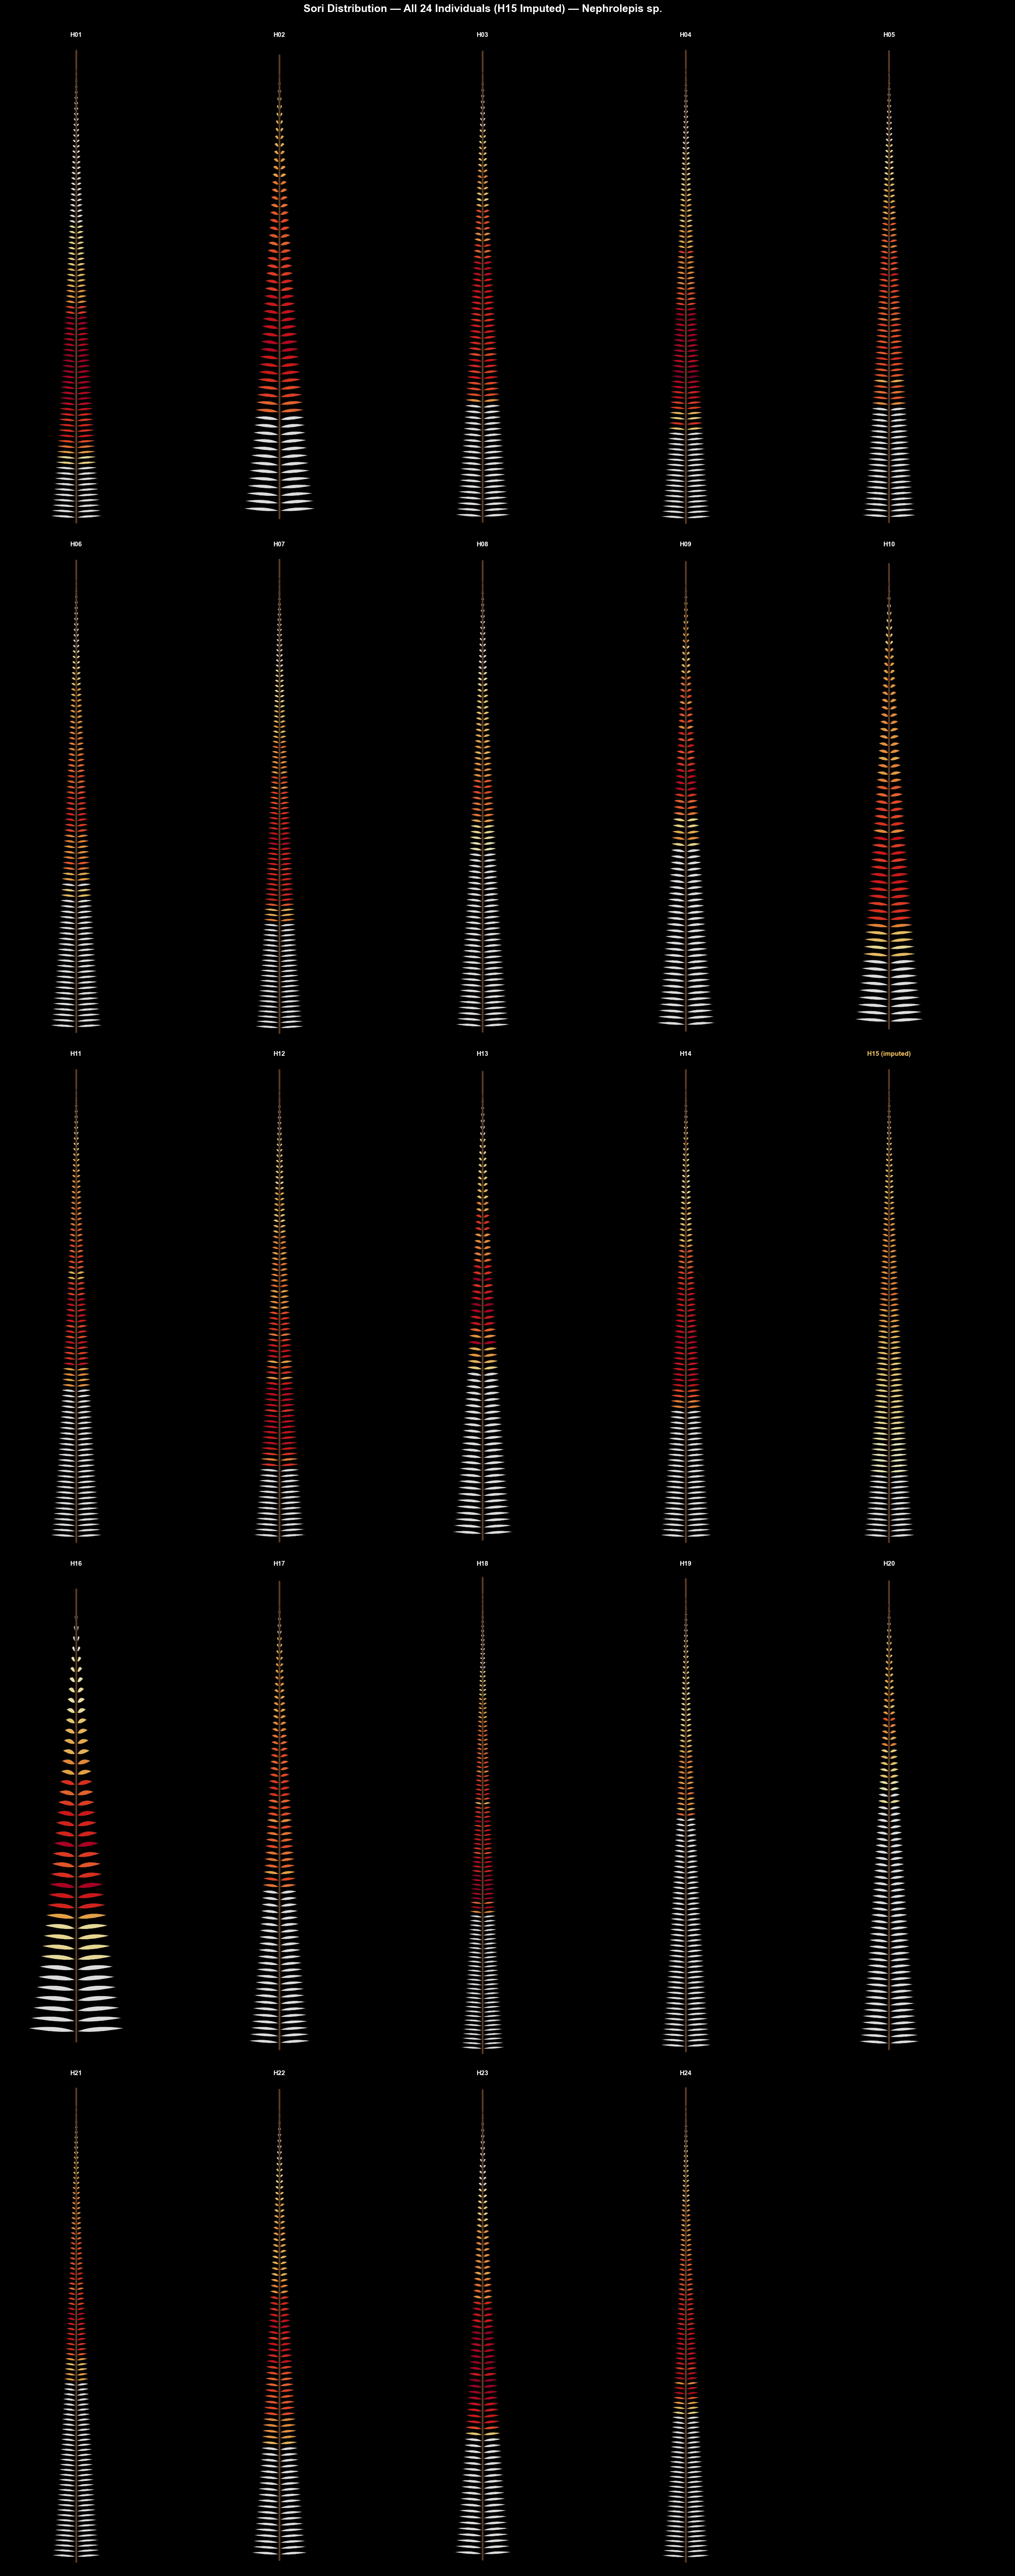

In [48]:
individuals_full = sorted(df_sori_imputed["individual_id"].unique())

fig, axes = plt.subplots(5, 5, figsize=(25, 60), facecolor="black")
axes = axes.flatten()

for i, individual in enumerate(individuals_full):
    axes[i].set_facecolor("black")
    heatmap_frond_ax(
        individual, axes[i], df_sori_imputed,
        is_imputed=(individual == "H15")
    )

for j in range(len(individuals_full), len(axes)):
    axes[j].set_facecolor("black")
    axes[j].axis("off")

plt.suptitle("Sori Distribution — All 24 Individuals (H15 Imputed) — Nephrolepis sp.",
             fontsize=18, fontweight="bold", color="white", y=1.001)

plt.tight_layout()
plt.savefig("../outputs/figures/03_full_population_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

`df_sori_imputed` now contains all 24 individuals (1921 rows total: 1835 real + 86 imputed for H15), with `is_imputed` flagging H15's rows for traceability. This is the final row-level dataset produced by this notebook.

## 9. Validating the Imputation Algorithm

### 9.1 Rationale: Leave-One-Out Validation

In Section 7.1 we used leave-one-out cross-validation to select K=9 by comparing *aggregate* performance across candidate K values. Now that K is fixed and H15's curve has already been generated, we run the same reconstruction procedure once more, this time examining *per-individual* results rather than just the dataset-wide average, to understand where the method performs well, where it struggles, and what that implies for how much to trust the imputed result for H15, which has no real curve to validate against directly.

### 9.2 LOO Reconstruction Function

No new function is needed here: `reconstruct_loo_curve`, defined in Section 7.1.3, already reconstructs any individual's distribution curve by excluding it (and H15) from the donor pool, using the same weighted-KNN procedure used to impute H15. We simply run it with `k=k_selected` (K=9) across all 23 individuals with complete data.

### 9.3 Running LOO Validation

In [49]:
loo_results = []

for test_individual in df_sori_notnull["individual_id"].unique():
    d_real = df_sori_notnull[df_sori_notnull.individual_id == test_individual].sort_values("row_id", ascending=True).reset_index(drop=True)
    real_counts = d_real["n_sori_per_row"].values
    real_proportion = real_counts / real_counts.sum()

    reconstructed_counts, reconstructed_proportion, _ = reconstruct_loo_curve(test_individual, k=k_selected)

    mae_count = np.mean(np.abs(real_counts - reconstructed_counts))
    mae_proportion = np.mean(np.abs(real_proportion - reconstructed_proportion))
    r_pearson, _ = pearsonr(real_proportion, reconstructed_proportion)

    loo_results.append({
        "individual_id": test_individual,
        "n_sori_total": int(real_counts.sum()),
        "mae_count": mae_count,
        "mae_proportion": mae_proportion,
        "pearson_r": r_pearson,
    })

df_loo = pd.DataFrame(loo_results).sort_values("pearson_r").reset_index(drop=True)
df_loo.round(3)

,individual_id,n_sori_total,mae_count,mae_proportion,pearson_r
0,H20,482,7.694,0.016,0.248
1,H01,1656,15.349,0.009,0.549
2,H09,1296,11.703,0.009,0.584
3,H12,1966,11.129,0.006,0.653
4,H10,1464,11.032,0.008,0.673
5,H21,1582,9.652,0.006,0.689
6,H16,802,10.381,0.013,0.711
7,H04,1826,11.348,0.006,0.719
8,H13,1170,9.833,0.008,0.726
9,H19,546,4.477,0.008,0.735


### 9.4 Results

Mean MAE (sori per row): 7.66 +/- 2.99
Mean MAE (relative proportion): 0.0061 +/- 0.0034
Mean Pearson correlation: 0.784 +/- 0.171
Worst case: H20 (r = 0.248)


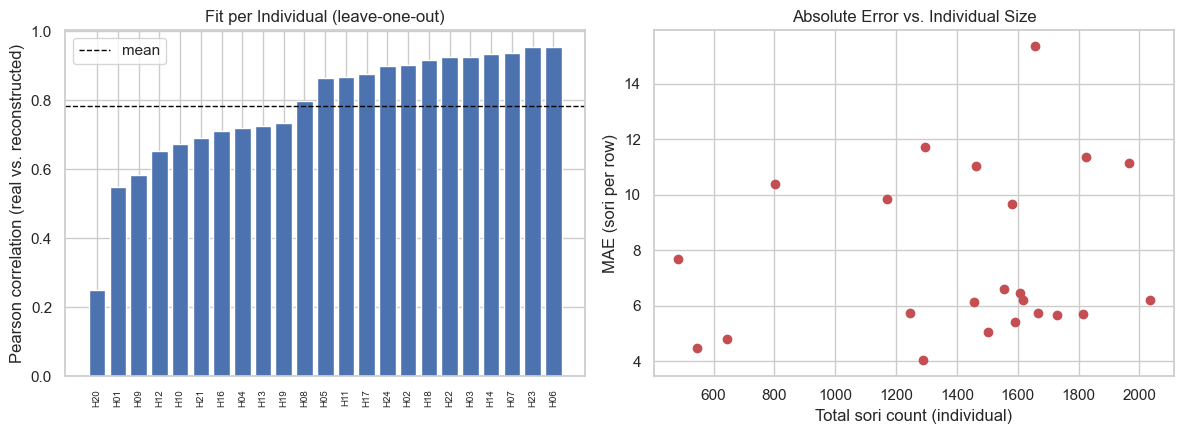

In [50]:
print(f"Mean MAE (sori per row): {df_loo['mae_count'].mean():.2f} +/- {df_loo['mae_count'].std():.2f}")
print(f"Mean MAE (relative proportion): {df_loo['mae_proportion'].mean():.4f} +/- {df_loo['mae_proportion'].std():.4f}")
print(f"Mean Pearson correlation: {df_loo['pearson_r'].mean():.3f} +/- {df_loo['pearson_r'].std():.3f}")
print(f"Worst case: {df_loo.iloc[0]['individual_id']} (r = {df_loo.iloc[0]['pearson_r']:.3f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Fit per individual
axes[0].bar(df_loo["individual_id"], df_loo["pearson_r"], color="#4c72b0")
axes[0].axhline(df_loo["pearson_r"].mean(), color="black", ls="--", lw=1, label="mean")
axes[0].tick_params(axis="x", rotation=90, labelsize=7)
axes[0].set_ylabel("Pearson correlation (real vs. reconstructed)")
axes[0].set_title("Fit per Individual (leave-one-out)")
axes[0].legend()

# Plot 2: Absolute error vs. individual size
axes[1].scatter(df_loo["n_sori_total"], df_loo["mae_count"], color="#c44e52")
axes[1].set_xlabel("Total sori count (individual)")
axes[1].set_ylabel("MAE (sori per row)")
axes[1].set_title("Absolute Error vs. Individual Size")

plt.tight_layout()
plt.show()

The leave-one-out validation (K=9) shows acceptable overall performance: a mean Pearson correlation of 0.784 ± 0.171 between real and reconstructed curves, with most individuals (20 of 23) above 0.65 and several exceeding 0.9. This supports that the weighted morphometric KNN reasonably captures the dominant sori-distribution pattern in the dataset.

However, the validation also exposes a real limitation of the method: the four worst-fitting cases (H20, H01, H09, H12; correlation between 0.25 and 0.65) share a distribution shape that departs from the "wide, centered bell" pattern that dominates the rest of the sample, narrow, asymmetrically positioned fertile zones instead. The error-vs-size scatter rules out individual size as the driver (no visible trend between total sori count and MAE); the issue is specifically one of shape, not scale. Since the KNN-donor approach reconstructs curves by averaging neighbors, it is systematically biased toward the dominant wide-centered shape and underperforms for individuals whose real pattern is narrow or off-center, a limitation worth stating explicitly when interpreting H15's imputed curve, since we cannot know which shape family H15 truly belongs to.

## 10. Export Imputed Dataset

We export `df_sori_imputed`, which includes the complete row-level sori distribution for all 24 individuals, 23 observed plus H15's imputed rows, with full traceability via `is_imputed`, so downstream notebooks or analyses can use the complete dataset directly.

In [51]:
df_sori_imputed.to_csv("../data/processed/sori_imputed.csv", index=False)

print(f"df_sori_imputed exported: {df_sori_imputed.shape[0]} rows × {df_sori_imputed.shape[1]} columns")

df_sori_imputed exported: 1921 rows × 6 columns


H15's row-level sori distribution has been imputed using a weighted morphometric KNN (K=9, selected via leave-one-out cross-validation), reconstructing its curve from the 9 real neighbors most similar to it in frond morphometrics. Leave-one-out validation shows the method performs well overall (mean Pearson r = 0.784), though it is systematically biased toward the dominant wide-centered distribution shape and underperforms for individuals with narrow, off-center fertile zones, a limitation to keep in mind when interpreting H15's imputed curve. The complete dataset, with full traceability of which values are imputed, is exported for use in downstream notebooks.